## Imports

In [1]:
import geohexgrid as ghg
import numpy as np
from shapely import Polygon, LineString
import geopandas as gpd
import pandas as pd
from math import comb, ceil
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
from typing import List, Tuple

## Grid

<Axes: >

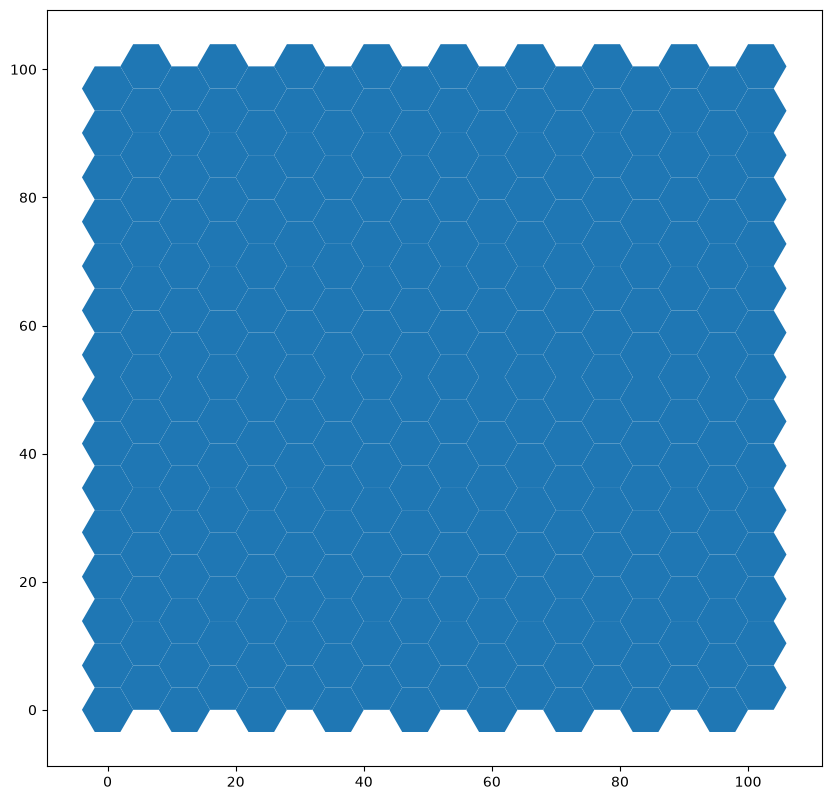

In [2]:
hex_radius = 4
grid = ghg.make_grid_from_bounds(0., 0., 100., 100., hex_radius)
grid['centroid'] = grid['geometry'].centroid
grid.plot(figsize=(10, 10))

<Axes: >

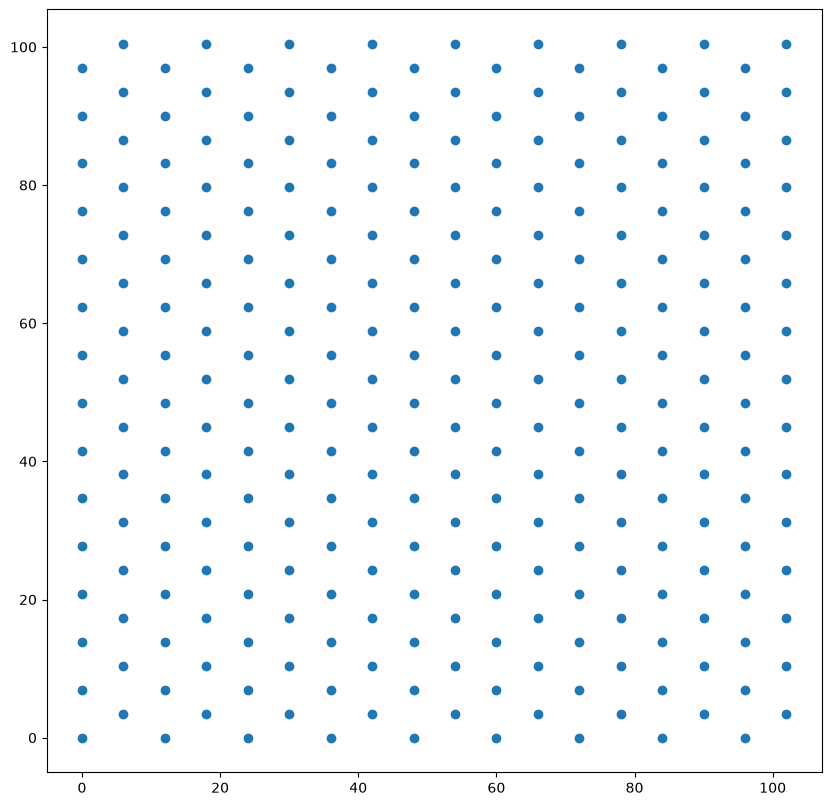

In [3]:
grid["centroid"].plot(figsize=(10, 10))

## Demand matrix

### Create all seed point pairs

In [4]:
def od_pairs(gdf: gpd.GeoDataFrame) -> gpd.GeoDataFrame:
    seed_points = gdf['cell_id'].values.tolist()
    geo = gdf['centroid'].values.tolist()
    n = len(seed_points)
    ids = []
    origins = []
    dests = []
    lines = []
    for i in range(n):
        for j in range(i+1, n):
            # print(f'seed_points[i]: {seed_points[i]}, seed_points[j]: {seed_points[j]}')
            # print(f'geo[i]: {geo[i]}, geo[j]: {geo[j]}')
            ids.append((seed_points[i], seed_points[j]))
            origins.append(seed_points[i])
            dests.append(seed_points[j])
            lines.append(LineString([geo[i], geo[j]]))
    return gpd.GeoDataFrame({'pair': ids, 'u': origins, 'v': dests, 'geometry': lines})

In [5]:
test_pairs = od_pairs(grid)
print(f'no. of seed points: {grid.shape[0]}')
print(f'no. of pairs is actually: {test_pairs.shape[0]}')
print(f'no. of pairs should be: {comb(grid.shape[0], 2)}')
test_pairs.head()

no. of seed points: 270
no. of pairs is actually: 36315
no. of pairs should be: 36315


,pair,u,v,geometry
0,"(0,0, 1,1)","0,0","1,1","LINESTRING (5.69767e-17 0, 6 3.4641)"
1,"(0,0, 2,0)","0,0","2,0","LINESTRING (5.69767e-17 0, 12 0)"
2,"(0,0, 3,1)","0,0","3,1","LINESTRING (5.69767e-17 0, 18 3.4641)"
3,"(0,0, 4,0)","0,0","4,0","LINESTRING (5.69767e-17 0, 24 0)"
4,"(0,0, 5,1)","0,0","5,1","LINESTRING (5.69767e-17 0, 30 3.4641)"


### Generate random demand

In [6]:
def generate_uniform_demand(n: int) -> np.ndarray:
    seed: int = 8920299146682435931
    rng: np.random.Generator = np.random.default_rng(seed=seed)
    return rng.uniform(low=0.0, high=1.0, size=n)

def make_demand_weird(demand: np.ndarray) -> np.ndarray:
    seed: int = 8920299146682435931
    rng: np.random.Generator = np.random.default_rng(seed=seed)
    n = len(demand)
    indices = [x for x in range(n)] 
    doubles = rng.choice(a=indices, size=int(n/4), replace=False)
    halves = rng.choice(a=indices, size=int(n/4), replace=False)
    for i in doubles:
        demand[i] = demand[i] * 2
    for i in halves:
        demand[i] = demand[i] / 1.5
    return demand

# Code from NumPy docs
def plot_demand_distribution(demand: np.ndarray):
    count, bins, _ = plt.hist(demand, 15, density=True)
    plt.plot(bins, np.ones_like(bins), linewidth=2, color='r')
    plt.show()

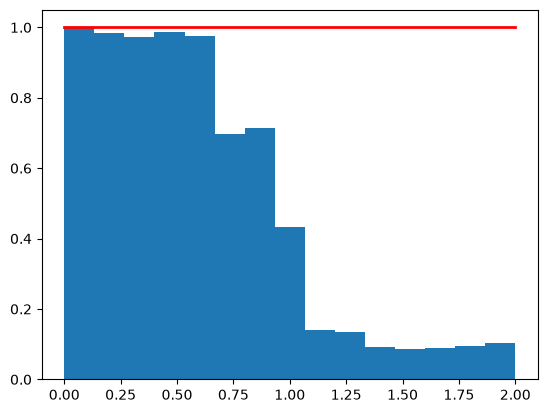

In [7]:
n_pairs = test_pairs.shape[0] # number of seed point pairs
test_demand = make_demand_weird(generate_uniform_demand(n_pairs))
plot_demand_distribution(test_demand)

### Create demand matrix

In [8]:
demand_matrix = pd.concat([test_pairs, pd.Series(test_demand)], axis=1)
demand_matrix.columns = ['pair', 'u', 'v', 'geometry', 'demand']
total_demand = float(demand_matrix['demand'].sum())
demand_matrix["demand_share"] = demand_matrix["demand"] * 100 / total_demand
print(demand_matrix.info())
demand_matrix.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 36315 entries, 0 to 36314
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   pair          36315 non-null  object  
 1   u             36315 non-null  str     
 2   v             36315 non-null  str     
 3   geometry      36315 non-null  geometry
 4   demand        36315 non-null  float64 
 5   demand_share  36315 non-null  float64 
dtypes: float64(2), geometry(1), object(1), str(2)
memory usage: 1.9+ MB
None


,pair,u,v,geometry,demand,demand_share
0,"(0,0, 1,1)","0,0","1,1","LINESTRING (5.69767e-17 0, 6 3.4641)",0.892246,0.004293
1,"(0,0, 2,0)","0,0","2,0","LINESTRING (5.69767e-17 0, 12 0)",0.958485,0.004612
2,"(0,0, 3,1)","0,0","3,1","LINESTRING (5.69767e-17 0, 18 3.4641)",0.777970,0.003743
3,"(0,0, 4,0)","0,0","4,0","LINESTRING (5.69767e-17 0, 24 0)",1.252564,0.006027
4,"(0,0, 5,1)","0,0","5,1","LINESTRING (5.69767e-17 0, 30 3.4641)",1.561905,0.007515


Text(0.5, 1.0, 'Seed point pairs')

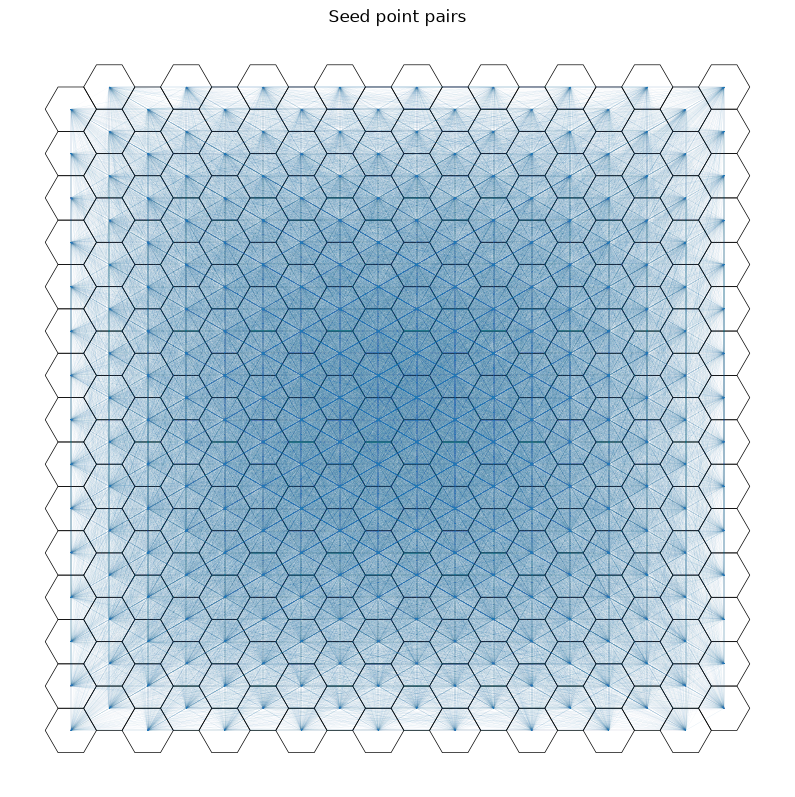

In [9]:
# With Anastassia's plot:
fig, ax = plt.subplots(1,1, figsize = (10,10))
grid.boundary.plot(ax=ax, color = "black", zorder = 0, lw = 0.5)
demand_matrix.plot(ax=ax, lw = demand_matrix.demand_share * 20, alpha = 0.2)
ax.set_axis_off()
ax.set_title("Seed point pairs")

## Seed point GDF

In [10]:
seed_points = grid
seed_points.columns = ['id', 'geometry', 'centroid']
seed_points["total_demand"] = seed_points.apply(
    lambda x:
        sum(demand_matrix[(demand_matrix.u == x.id) | (demand_matrix.v == x.id)].demand),
    axis = 1
)
print(seed_points.info())
seed_points.head()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 270 entries, 0 to 269
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   id            270 non-null    str     
 1   geometry      270 non-null    geometry
 2   centroid      270 non-null    geometry
 3   total_demand  270 non-null    float64 
dtypes: float64(1), geometry(2), str(1)
memory usage: 9.7 KB
None


,id,geometry,centroid,total_demand
0,"0,0","POLYGON ((-2 -3.4641, 2 -3.4641, 4 0, 2 3.4641...",POINT (5.69767e-17 0),144.630881
1,"1,1","POLYGON ((4 0, 8 0, 10 3.4641, 8 6.9282, 4 6.9...",POINT (6 3.4641),159.760828
2,"2,0","POLYGON ((10 -3.4641, 14 -3.4641, 16 0, 14 3.4...",POINT (12 0),156.240549
3,"3,1","POLYGON ((16 0, 20 0, 22 3.4641, 20 6.9282, 16...",POINT (18 3.4641),149.703474
4,"4,0","POLYGON ((22 -3.4641, 26 -3.4641, 28 0, 26 3.4...",POINT (24 0),143.611325


Text(0.5, 1.0, 'Total demand per hexagon')

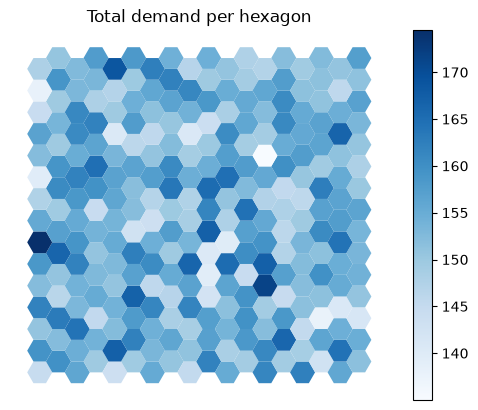

In [11]:
fig, ax = plt.subplots(1,1)
seed_points.plot(
    ax=ax,
    column="total_demand",
    cmap = "Blues",
    legend=True
)
ax.set_axis_off()
ax.set_title("Total demand per hexagon")

## Initial Route Set Generation

### Variables

In [12]:
N_ITE: int = 100            # iterations
N_POP: int = 20
MAX_PATHS: int = 10
MAX_NODES: int = 15
SEED: int = 3581054352
RNG: np.random.Generator = np.random.default_rng(seed=SEED)
ROOT = '../../'
PATH = ROOT + 'output/plots/'

### Helper functions

TODO: Use spatial indexing to find neighbours instead? Sth with trees?

In [13]:
def numeric_id(s: str) -> Tuple[int, int]:
    x, y = s.split(",")
    return int(x), int(y)

def str_id(t: Tuple[int, int]) -> str:
    return f'{t[0]},{t[1]}'

# Inspired by Red Blob Games
hex_directions = [
    (1, 0), (1, -1), (0, -1), 
    (-1, 0), (-1, 1), (0, 1)
]

def hex_direction(direction):
    return hex_directions[direction]

def hex_add(a, b):
    return a[0] + b[0], a[1] + b[1]

def hex_neighbour(hex, direction):
    return hex_add(hex, hex_direction(direction))

def axial_to_cube(q, r):
    s = -q-r
    return (q, r, s)

def cube_to_axial(q, r, s):
    assert not (round(q + r + s) != 0), "q + r + s must be 0"
    return (q, r)

def double_to_axial(node: Tuple[int, int]) -> Tuple[int, int]:
    u, v = node
    x, y = ghg.double_to_cartesian(u, v, hex_radius)
    return ghg.cartesian_to_axial(x, y, hex_radius)

# TODO: should only add neighbours to vns if they are in the dataset, i.e. within the bounding box
def vns(node: Tuple[int, int]) -> List[Tuple[int, int]]:
    q, r = double_to_axial(node)
    vns = []
    for i in range(6):
        a, b = hex_neighbour((q, r), i)
        neighbour = ghg.axial_to_double(a, b)
        vns.append(str_id(neighbour))
    return vns

### Create Vicinity Node Set (VNS) for each seed point / hexagon

In [14]:
seed_points["vns"] = seed_points["id"].apply(lambda s: vns(numeric_id(s)))

### Functions to create single network

In [15]:
def normalise_probabilities(df):
    p = df.to_numpy(dtype=np.float64)
    return p / np.sum(p, dtype=np.float64)

# TODO: bias terms for each node in the VNS?
# TODO: needs some way to stop if no node in VNS is possible. boolean in irs dict?
def next_node(p: int, previous_node: str, irs: dict):
    # Calculate probabilities for each node in the VNS
    filter = seed_points.loc[seed_points['id'] == previous_node, ['vns']].values.tolist()[0][0]
    vns = seed_points.loc[seed_points['id'].isin(filter)].sort_values(by=['total_demand'], ascending=False)
    activity_sum = float(vns['total_demand'].sum()) 
    vns['probability'] = vns['total_demand'] / activity_sum

    # Select next node and add to dict
    tries = vns.shape[0]
    next_node = ''
    for _ in range(tries):
        next_node = RNG.choice(a=vns['id'], p=normalise_probabilities(vns['probability']))
        if next_node not in irs[p]['nodes']:
            irs[p]['nodes'].append(next_node)
            break
        else:
            vns = vns[(vns['id'] != next_node)]
    finished = vns.shape[0] == 0 # stop if no node in VNS is possible
    return (next_node, irs, finished)

def generate_route(k: int):
    """
    Form Initial Node Set (INS) from the first k nodes. k must be larger than MAX_PATHS
    """
    irs = {}
    ins = seed_points.copy().sort_values("total_demand", ascending=False).head(k).reset_index(drop=True)

    # Select first nodes
    for i in range(MAX_PATHS):
        # Calculate probabilities of selection a node j as first node
        activity_sum = float(ins['total_demand'].sum())
        ins['probability'] = ins['total_demand'] / activity_sum
    
        # Select first node
        first_node = RNG.choice(a=ins['id'], p=normalise_probabilities(ins['probability']))
    
        # Add to dict
        irs[i] = {'nodes': [first_node]}
    
        # Remove selected node from INS
        ins = ins[(ins['id'] != first_node)]

        # Build paths
        previous_node = first_node
        for _ in range(MAX_NODES-1): # -1 because we already added first_node
            tmp_next, tmp_irs, finished = next_node(i, previous_node, irs)
            if finished: # stop if no node in VNS is possible
                break
            previous_node = tmp_next
            irs = tmp_irs

    return irs

def create_gdf(irs: dict) -> gpd.GeoDataFrame:
    # Create dict for network
    d = {
        'path_id': [path_id for path_id in irs],
        'start_id': [path.get('nodes')[:][0] for _, path in irs.items()],
        'end_id': [path.get('nodes')[:][-1] for _, path in irs.items()],
        'path': [path.get('nodes') for _, path in irs.items()],
        #'demand_covered': [],
        #'geometry': []
    }

    # Create geometries
    id_to_centroid = seed_points.set_index("id")["centroid"].to_dict()
    geom = [
        LineString([id_to_centroid[point_id] for point_id in path])
        for path in d['path']
    ]

    # Create dataframe
    network_gdf = gpd.GeoDataFrame(d, geometry=geom, crs=None)

    return network_gdf

def generate_population(n: int, k: int) -> gpd.GeoDataFrame:
    """
    Create population of n networks (route sets).
    Each network will contain the starting nodes selected from the k nodes with highest demand.
    """
    pop_list = []
    for i in range(n):
        gdf = create_gdf(generate_route(k))
        gdf['network_id'] = i
        # save_plot(gdf)
        pop_list.append(gdf)


    pop_gdf = pd.concat(pop_list)
    # save as geojson here
    return pop_gdf

### Run IRSG

In [16]:
n_start_nodes = int(len(seed_points)/2) # how many start nodes do we initialise our routes with
start_pop = generate_population(N_POP, n_start_nodes)

### Plot start population

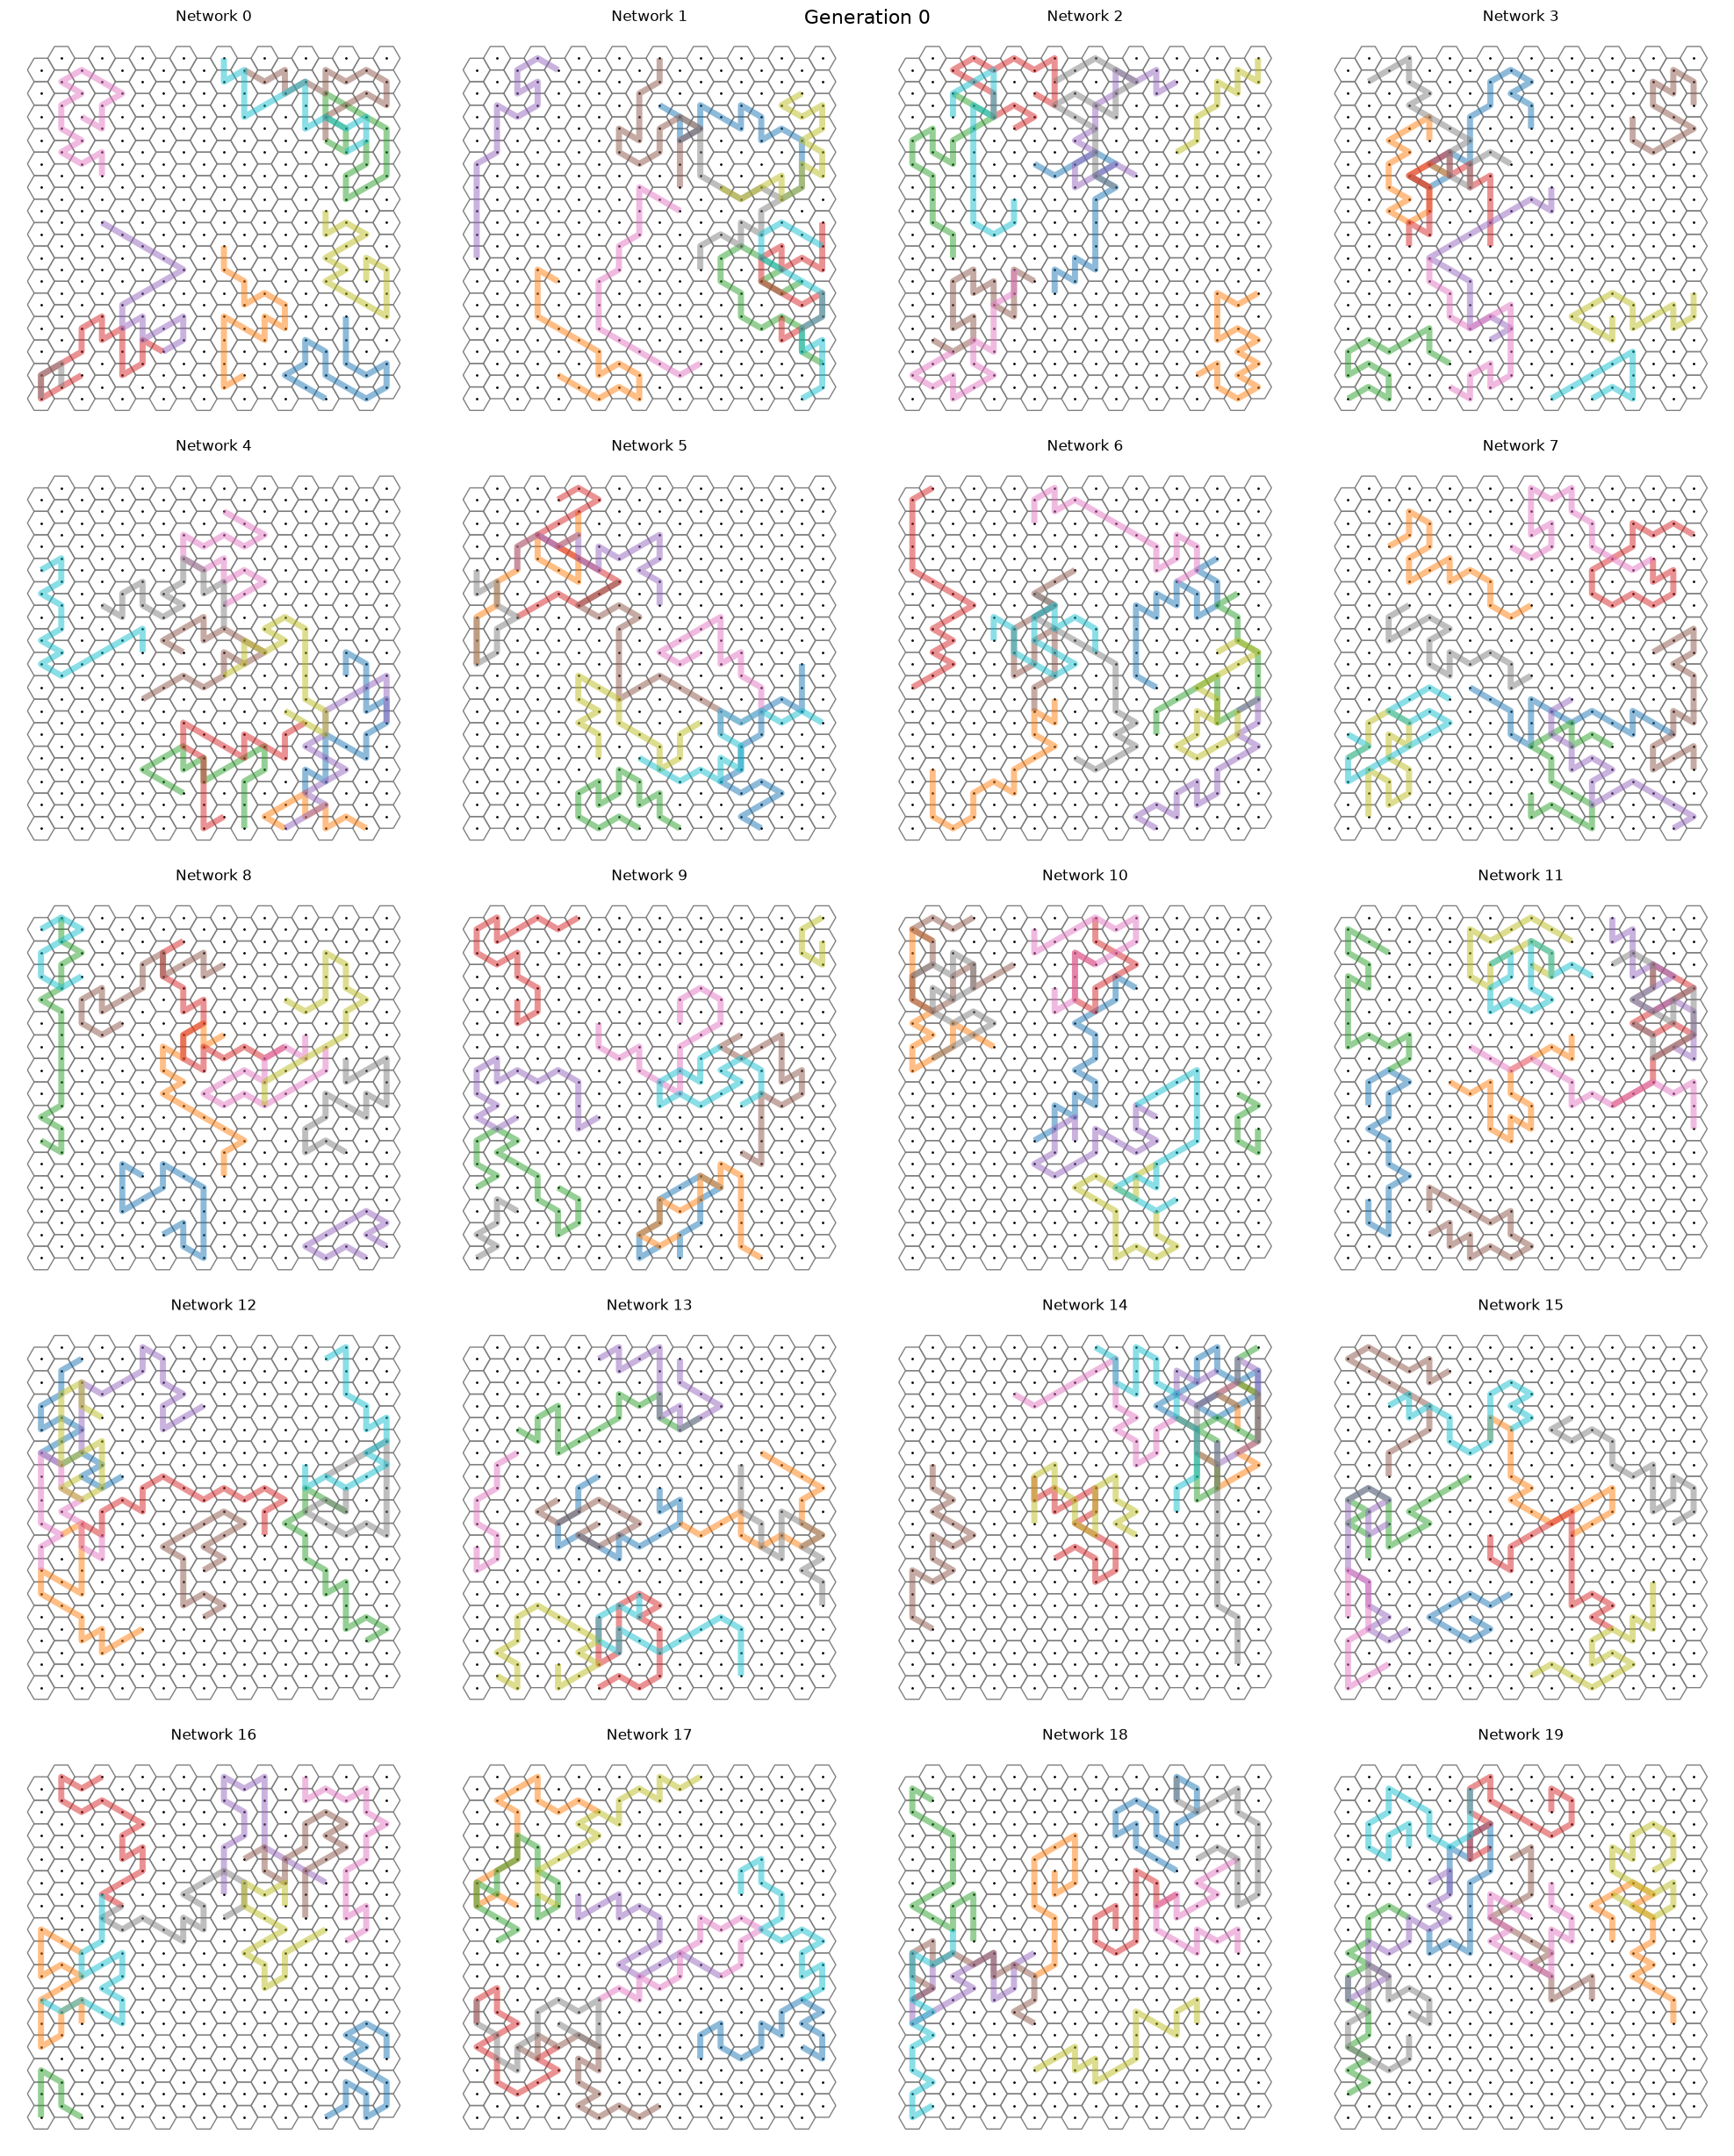

In [17]:
n_cols = 4
n_rows = ceil(N_POP / n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows))
axes = axes.ravel()

cmap = mpl.colormaps.get_cmap('tab10')

for i in range(N_POP):
    ax = axes[i]
    network = start_pop[start_pop['network_id'].values == i]
    colors = cmap(np.linspace(0, 1, len(network)))
    seed_points.boundary.plot(ax=ax, color = "grey", lw = 1)
    grid['centroid'].plot(ax=ax, color = "black", markersize=1)

    for path_id in network['path_id']:
        network[network['path_id']==path_id].plot(
            ax=ax,
            lw=5,
            alpha = 0.5,
            label=path_id,
            color=colors[path_id])
        
    # ax.legend()
    ax.set_title(f"Network {i}")
    ax.set_axis_off()

fig.suptitle("Generation 0", fontsize=16)
plt.tight_layout()

filename = f'start_population'
plt.savefig(f"{PATH}{filename}.png", dpi=300, bbox_inches='tight')
plt.show()